# LFANet-NoResidual Ablation Study

In [4]:
import cv2
import os
import numpy as np
import pandas as pd
from math import exp, sqrt
import matplotlib.pyplot as plt
from sklearn import svm, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.utils.multiclass import unique_labels
import matplotlib.image as mpimg
from sklearn.utils import shuffle
import keras
import tensorflow as tf

import tensorflow.keras.backend as K
from keras import Input
from keras.models import Model
from keras.layers import Dense, Dropout, Activation, Flatten
from keras.layers import  BatchNormalization, Concatenate, Add, DepthwiseConv2D, GlobalAveragePooling2D, SeparableConv2D
from tensorflow.keras.optimizers import SGD,RMSprop,Adam,Adagrad
from keras.layers import Conv2D, MaxPooling2D

from tensorflow.keras.layers import Dense, Reshape, Softmax, Permute, Add, Lambda
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import roc_curve, auc, roc_auc_score, classification_report
from sklearn.preprocessing import label_binarize
from PIL import Image
from zipfile import ZipFile
import shutil
import seaborn as sns
import time
from datetime import datetime

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("vibhingupta028/liver-histopathology-fibrosis-ultrasound-images")

# print("Path to dataset files:", path)

# Change this to your dataset location in Google Drive
path = "/content/drive/MyDrive/Liver Fibrosis/Dataset"

print("Dataset path:", path)
print("Folders:", os.listdir(path))

Dataset path: /content/drive/MyDrive/Liver Fibrosis/Dataset
Folders: ['F4', 'F2', 'F1', 'F0', 'F3']


# **Splitting the Data into Training and Testing**

In [7]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from keras.utils import to_categorical

# Define class names
class_names = ['F0', 'F1', 'F2', 'F3', 'F4']
class_to_label = {name: idx for idx, name in enumerate(class_names)}

img_data_list = []
labels = []

# Load images and labels
# The base path is already '/content/drive/MyDrive/Liver Fibrosis/Dataset'
# The images are directly in subfolders like 'F0', 'F1' etc. under this path.
for dataset in class_names:
    current_dataset_path = os.path.join(path, dataset)
    img_list = os.listdir(current_dataset_path)
    print(f'Loaded images from dataset-{dataset}, total: {len(img_list)}')

    for img_filename in img_list:
        # Correctly form the image path
        img_path = os.path.join(current_dataset_path, img_filename)
        input_img = cv2.imread(img_path)
        if input_img is None:
            # print(f"Warning: Could not load image {img_path}") # Optional: uncomment for debugging specific missing images
            continue
        input_img_resize = cv2.resize(input_img, (128, 128))
        img_data_list.append(input_img_resize)
        labels.append(class_to_label[dataset])  # Use mapped label

Loaded images from dataset-F0, total: 2114
Loaded images from dataset-F1, total: 861
Loaded images from dataset-F2, total: 793
Loaded images from dataset-F3, total: 857
Loaded images from dataset-F4, total: 1708


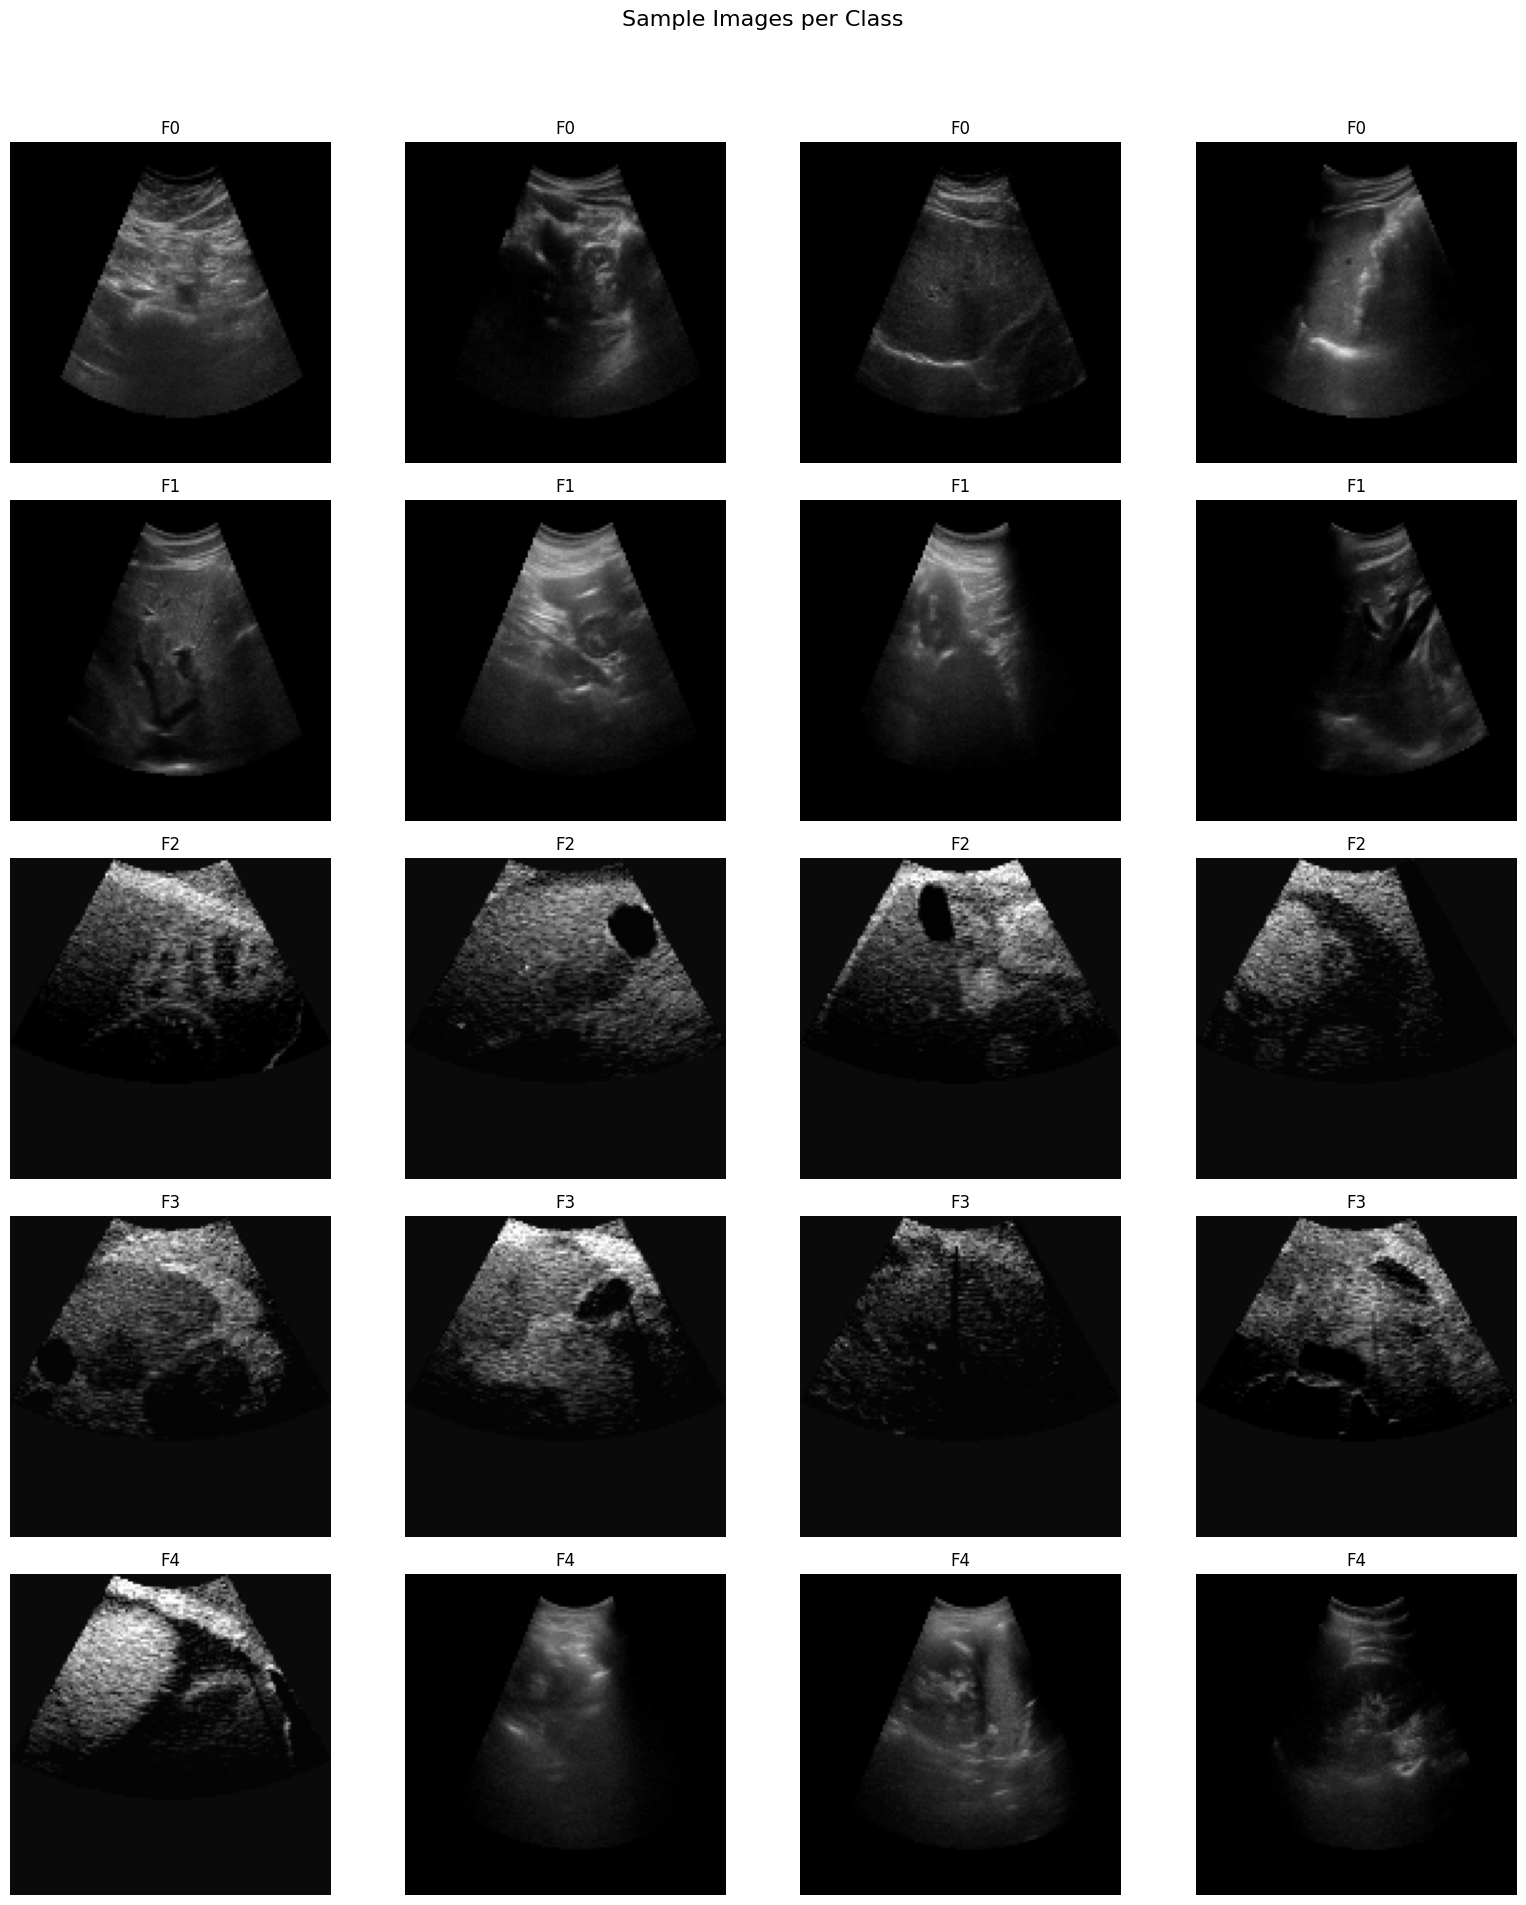

In [8]:
import matplotlib.pyplot as plt
import random

num_images_per_class = 4
plt.figure(figsize=(16, 4 * len(class_names)))

for idx, class_name in enumerate(class_names):
    class_indices = [i for i, label in enumerate(labels) if label == idx]
    sampled_indices = random.sample(class_indices, min(num_images_per_class, len(class_indices)))

    for j, rand_idx in enumerate(sampled_indices):
        plt_idx = idx * num_images_per_class + j + 1
        plt.subplot(len(class_names), num_images_per_class, plt_idx)
        plt.imshow(img_data_list[rand_idx])
        plt.title(class_name)
        plt.axis('off')

plt.suptitle("Sample Images per Class", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [9]:
data = np.array(img_data_list, dtype="float32") / 255.0
labels = np.array(labels)

# Check if data is empty before proceeding
if data.shape[0] == 0:
    raise ValueError("No image data loaded. Please check the previous cell (cell 3bbdaedc) to ensure images are being loaded correctly by verifying the `dataset_path` variable.")

# One-hot encode labels
num_classes = len(class_names)
labels_one_hot = to_categorical(labels, num_classes)

# Train / temp split (70 / 30)
x_train, x_temp, y_train, y_temp = train_test_split(
    data,
    labels_one_hot,
    test_size=0.3,
    stratify=labels,
    random_state=42
)

# Stratify validation / test split (15 / 15)
y_temp_labels = np.argmax(y_temp, axis=1)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp_labels,
    random_state=42
)

# Shuffle
x_train, y_train = shuffle(x_train, y_train, random_state=42)
x_val, y_val = shuffle(x_val, y_val, random_state=42)
x_test, y_test = shuffle(x_test, y_test, random_state=42)

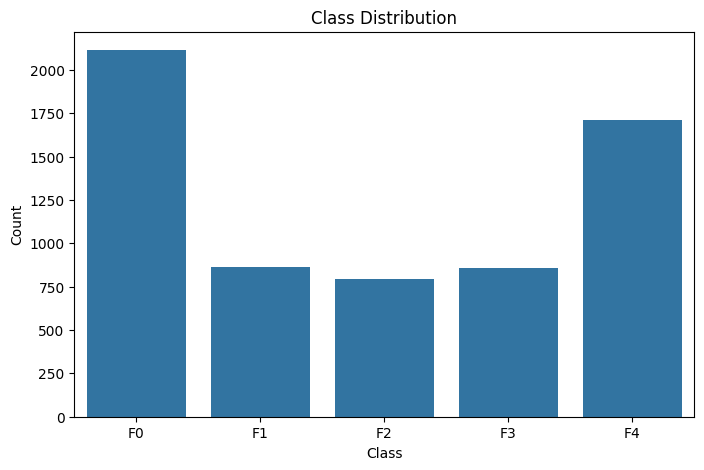

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot class distribution
plt.figure(figsize=(8, 5))
sns.countplot(x=np.argmax(labels_one_hot, axis=1))
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(ticks=range(num_classes), labels=class_names)
plt.show()

In [11]:
# Reshape
x_train = x_train.reshape(-1, 128, 128, 3)
x_val = x_val.reshape(-1, 128, 128, 3)
x_test = x_test.reshape(-1, 128, 128, 3)

# Confirm shapes
print("Train shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Test shape:", x_test.shape)

Train shape: (4433, 128, 128, 3)
Validation shape: (950, 128, 128, 3)
Test shape: (950, 128, 128, 3)


In [12]:
import tensorflow
METRICS = [tensorflow.keras.metrics.CategoricalAccuracy(name='accuracy'),
           tensorflow.keras.metrics.Precision(name='precision'),
           tensorflow.keras.metrics.Recall(name='recall'),
           tensorflow.keras.metrics.AUC(name='auc')]

In [13]:
from tensorflow.keras.layers import Dense, Reshape, Softmax, Permute, Add, Lambda
import tensorflow.keras.backend as K

def self_attention(input_feature_map):
    shape = K.int_shape(input_feature_map)  # (batch_size, height, width, channels)
    batch_size, height, width, channels = shape

    # Flatten the spatial dimensions (height, width) to treat them as sequence elements
    flat_feature_map = Reshape((height * width, channels))(input_feature_map)  # (batch_size, height*width, channels)

    # Compute Query, Key, and Value matrices with more complexity
    query_dense1 = Dense(channels // 4, activation='relu')(flat_feature_map)   # (batch_size, height*width, channels // 4)
    key_dense1 = Dense(channels // 4, activation='relu')(flat_feature_map)     # (batch_size, height*width, channels // 4)
    value_dense1 = Dense(channels // 2, activation='relu')(flat_feature_map)   # (batch_size, height*width, channels // 2)

    query = Dense(channels // 8)(query_dense1)  # (batch_size, height*width, channels // 8)
    key = Dense(channels // 8)(key_dense1)      # (batch_size, height*width, channels // 8)
    value = Dense(channels)(value_dense1)       # (batch_size, height*width, channels)

    # Transpose the Key for dot product
    key_transposed = Permute((2, 1))(key)  # (batch_size, channels // 8, height*width)

    # Compute attention scores (dot product between Query and transposed Key)
    attention_scores = Lambda(lambda x: K.batch_dot(x[0], x[1]),
                              output_shape=(height * width, height * width))([query, key_transposed])

    # Apply softmax to the attention scores
    attention_scores = Softmax()(attention_scores)  # (batch_size, height*width, height*width)

    # Apply the attention scores to the Value matrix
    attention_output = Lambda(lambda x: K.batch_dot(x[0], x[1]),
                              output_shape=(height * width, channels))([attention_scores, value])  # (batch_size, height*width, channels)

    # Reshape the attention output back to the original feature map shape
    attention_output = Reshape((height, width, channels))(attention_output)

    # Add the input to the attention output (residual connection)
    output = Add()([input_feature_map, attention_output])

    return output

In [14]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Conv2D, BatchNormalization, ReLU, DepthwiseConv2D, Multiply,
    Concatenate, GlobalAveragePooling2D, Dense, Activation, Add, Dropout
)
from tensorflow.keras.models import Model

# Input Layer
input_layer = tf.keras.Input(shape=(128, 128, 3))

# Initial Convolution Block
x = Conv2D(32, (3, 3), strides=(2, 2), padding='same', activation='relu')(input_layer)
x = BatchNormalization()(x)
x = Conv2D(64, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)

# Depthwise Separable Convolution Block
x = DepthwiseConv2D((3, 3), padding='same', strides=(1, 1))(x)
x = BatchNormalization()(x)
x = ReLU()(x)

# Dilated Convolution Branches for Multi-scale Features
x1 = Conv2D(128, (3, 3), dilation_rate=1, padding='same', activation='relu')(x)
x1 = BatchNormalization()(x1)
x2 = Conv2D(128, (3, 3), dilation_rate=3, padding='same', activation='relu')(x)
x2 = BatchNormalization()(x2)
x3 = Conv2D(128, (3, 3), dilation_rate=5, padding='same', activation='relu')(x)
x3 = BatchNormalization()(x3)

# Adding Branch Outputs
A1 = Add()([x1, x2, x3])

# Intermediate Convolutional Block
x4 = Conv2D(128, (3, 3), padding='same', activation='relu')(A1)
x4 = BatchNormalization()(x4)

x = self_attention(x4)

# Concatenation Block
C1 = Concatenate()([x, x2, x3])
x5 = Conv2D(128, (3, 3), padding='same', activation='relu')(C1)

# Residual Connection
C2 = Concatenate()([x5, x])
x = Conv2D(256, (3, 3), padding='same', activation='relu')(C2)
x = BatchNormalization()(x)

# Expanded Depthwise Separable Convolution Block
x = DepthwiseConv2D((3, 3), padding='same', strides=(1, 1))(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = Conv2D(256, (1, 1), padding='same', activation='relu')(x)
x = BatchNormalization()(x)

# Additional Residual Connection (removed for ablation study)
# residual = Conv2D(256, (1, 1), padding='same', activation='relu')(C2)
# x = Add()([x, residual])
# Continue the forward pass without the residual addition

# Further Convolutional Layers
x = Conv2D(256, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = Conv2D(512, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)

# Global Pooling
x = GlobalAveragePooling2D()(x)

# Fully Connected Layers
x = Dense(512, activation='relu')(x)
x = Dense(256, activation='relu')(x)
output = Dense(5, activation='softmax')(x)

# Model Compilation
model_no_residual = Model(inputs=input_layer, outputs=output)
model_no_residual.compile(optimizer='adam', loss='categorical_crossentropy', metrics= METRICS)
model_no_residual.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     18,496 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d    │ (None, 64, 64,    │        640 │ batch_normalizat… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ re_lu[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     73,856 │ re_lu[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ re_lu[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    147,584 │ add[0][0]         │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 3,690,341 (14.08 MB)

 Trainable params: 3,685,925 (14.06 MB)

 Non-trainable params: 4,416 (17.25 KB)

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

In [16]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

In [17]:
from tensorflow.keras.callbacks import ModelCheckpoint
checkpoint_no_residual = ModelCheckpoint(
    filepath='model_no_residual-{epoch:03d}-{accuracy:.3f}-{val_accuracy:.3f}.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

In [18]:
import time
start_train = time.time()
history = model_no_residual.fit(x_train, y_train, batch_size = 16, epochs = 1,
                    validation_data = (x_val , y_val), callbacks=[early_stop, lr_scheduler, checkpoint_no_residual], verbose =1)
end_train = time.time()
training_time = end_train - start_train
print(f"\nTraining time: {training_time:.2f} seconds")

278/278 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.5278 - auc: 0.8404 - loss: 1.0779 - precision: 0.6954 - recall: 0.3739
Epoch 1: val_accuracy improved from None to 0.27053, saving model to model_no_residual-001-0.590-0.271.keras

Epoch 1: finished saving model to model_no_residual-001-0.590-0.271.keras
278/278 ━━━━━━━━━━━━━━━━━━━━ 188s 501ms/step - accuracy: 0.5903 - auc: 0.8794 - loss: 0.9427 - precision: 0.7779 - recall: 0.4392 - val_accuracy: 0.2705 - val_auc: 0.4606 - val_loss: 4.6006 - val_precision: 0.2705 - val_recall: 0.2705 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 1.

Training time: 213.69 seconds


In [19]:
loss, acc, prec, rec, auc = model_no_residual.evaluate(x_test, y_test)

30/30 ━━━━━━━━━━━━━━━━━━━━ 47s 831ms/step - accuracy: 0.2695 - auc: 0.4633 - loss: 4.6022 - precision: 0.2695 - recall: 0.2695


In [20]:
# -----------------------------------------------------------------
# INFERENCE TIME (measure prediction speed)
# -----------------------------------------------------------------
start_inf = time.time()
preds = model_no_residual.predict(x_test)
end_inf = time.time()

inference_time = end_inf - start_inf
print(f"\nInference time on test set: {inference_time:.2f} seconds")

# Milliseconds per image
ms_per_image = (inference_time / len(x_test)) * 1000
print(f"Milliseconds per image: {ms_per_image:.2f} ms")

30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 313ms/step

Inference time on test set: 13.13 seconds
Milliseconds per image: 13.83 ms


In [21]:
# -----------------------------------------------------------------
# SAVE MODEL AND CHECK SIZE
# -----------------------------------------------------------------
import os
import tensorflow as tf
from datetime import datetime

os.makedirs("saved_models_no_residual", exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Version 1: deployment-safe HDF5
h5_path = f"saved_models_no_residual/livermodel_no_residual_{timestamp}.h5"
model_no_residual.save(h5_path)
print(f"Saved H5 model: {h5_path}")

# Version 2: TensorFlow SavedModel (optional, backup)
tf_path = f"saved_models_no_residual/livermodel_tf_no_residual_{timestamp}"
# Use model.export for TensorFlow SavedModel format
model_no_residual.export(tf_path)
print(f"Saved TF model: {tf_path}")

# Version 3: Keras v3 format (only if you want it)
keras_path = f"saved_models_no_residual/livermodel_no_residual_{timestamp}.keras"
model_no_residual.save(keras_path)
print(f"Saved Keras model: {keras_path}")

model_size_mb = os.path.getsize(keras_path) / (1024 * 1024)
print(f"Model size: {model_size_mb:.2f} MB")

Saved H5 model: saved_models_no_residual/livermodel_no_residual_20260709_050805.h5
Saved artifact at 'saved_models_no_residual/livermodel_tf_no_residual_20260709_050805'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  135627818866576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135627818869456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135627818870992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135627818871952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135627818871760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135627818871184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135627818871568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135627818872144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135627818867536: Tens

In [22]:
from sklearn.metrics import classification_report
import numpy as np

# Convert one-hot encoded y_test to class labels
y_true_labels = np.argmax(y_test, axis=1)

# Convert predicted probabilities to class labels
y_pred_labels = np.argmax(preds, axis=1)

# Generate classification report
report = classification_report(
    y_true_labels,
    y_pred_labels,
    target_names=class_names,
    zero_division=0
)

print("\nClassification Report:")
print(report)


Classification Report:
              precision    recall  f1-score   support

          F0       0.00      0.00      0.00       317
          F1       0.00      0.00      0.00       129
          F2       0.00      0.00      0.00       119
          F3       0.00      0.00      0.00       129
          F4       0.27      1.00      0.42       256

    accuracy                           0.27       950
   macro avg       0.05      0.20      0.08       950
weighted avg       0.07      0.27      0.11       950

